[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/data-engineering-from-scratch-to-advanced/blob/main/notebooks/topics/02_python-for-de.ipynb)

*Data Engineering from Scratch to Advanced · Notebook 2 of 21*

# Python for Pipelines

The Python a data engineer uses every day: dates and time zones, processing files too big for memory with generators, batching, retries, validation, logging and writing code you can test.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** Treat data as a stream passing through, never a bucket you must lift. One item at a time, and memory stays flat.

**What interviewers really test here:** Generators, dates and time zones, retries, handling bad rows, and code you can test.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. Handling files bigger than your memory *(Basics)*
- [ ] 2. Dates and time zones: where bugs live *(Basics)*
- [ ] 3. Failures: retries, validation and bad data *(Core)*
- [ ] 4. Writing pipeline code that lasts *(Core)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import math
import numpy as np
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Libraries worth knowing

| Library | Used for |
| --- | --- |
| csv, json, gzip, pathlib | reading and writing files |
| datetime, zoneinfo | dates and time zones |
| logging | recording what happened |
| pytest | testing |
| requests / httpx | calling APIs |
| pandas, polars, pyarrow | data on one machine, and Parquet |
| sqlalchemy, psycopg | talking to databases |
| boto3 | AWS services |

---
# Part 2: Lessons, step by step

## Lesson 1: Handling files bigger than your memory

*Level: Basics*

You've written `data = open("file").read()`. On a 50 GB file with a 16 GB laptop, that crashes. The fix is the most useful Python idea in data engineering: **process one piece at a time**.



```python
with open("huge.log") as f:
    for line in f:           # reads one line at a time
        handle(line)
```



**Generators** let you build pipelines of steps that hold almost nothing in memory. `yield` hands out one value and pauses:



```python
def parse(lines):
    for line in lines:
        try:
            yield float(line.split(",")[1])
        except (IndexError, ValueError):
            continue          # skip bad lines (better: count them!)

total = sum(a for a in parse(open("huge.csv")) if a > 5)
```



By hand, for "a,10", "bad", "b,x", "c,3", "d,20" with minimum 5: parse yields 10, 3 and 20, the filter keeps 10 and 20, and the total is **30**. Only one value exists at a time.



The chart compares memory use. A list grows with the data, while a generator stays flat.



**Writing in batches.** A database insert per row is slow, while a huge insert can fail. So group rows: 7 rows in batches of 3 gives [0,1,2], [3,4,5], [6]. Don't forget that last partial batch, which is a very common bug.



**Top K and merging** also avoid loading everything. A heap of size k finds the top k from any size of stream, using memory for only k items. `heapq.merge` merges sorted files holding just one item per file.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

list of 1,000,000 uses 8448728 bytes; generator uses 200


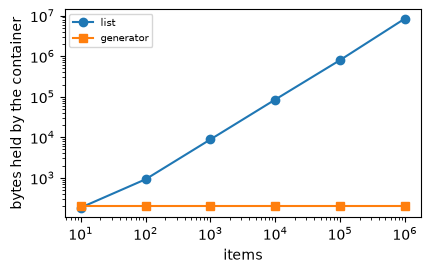

In [2]:
def memory_of_list_vs_generator():
    import sys
    sizes = [10 ** k for k in range(1, 7)]
    lists = [sys.getsizeof([i for i in range(n)]) for n in sizes]
    gens = [sys.getsizeof(i for i in range(n)) for n in sizes]
    print("list of 1,000,000 uses", lists[-1], "bytes; generator uses", gens[-1])
    fig, ax = plt.subplots(figsize=(4.6, 2.7))
    ax.loglog(sizes, lists, "o-", label="list")
    ax.loglog(sizes, gens, "s-", label="generator")
    ax.set_xlabel("items")
    ax.set_ylabel("bytes held by the container")
    ax.legend(fontsize=7)


memory_of_list_vs_generator()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q9](#q9), [Q15](#q15), [Q16](#q16), [Q20](#q20). Try one now, or carry on and do them in Part 3.

## Lesson 2: Dates and time zones: where bugs live

*Level: Basics*

Date bugs are probably the most common in pipelines. Three rules prevent most of them.



**Rule 1: store everything in UTC.** Convert to local time only for display. 01:30 in India (+05:30) on 5 January is 20:00 UTC on **4 January**, so a different day. Grouping by the wrong one puts revenue on the wrong date.



**Rule 2: know which time you mean.**



| Time | Meaning |
| --- | --- |
| Event time | when it actually happened |
| Ingestion time | when your system received it |
| Processing time | when you processed it |



A phone offline for 3 hours sends yesterday's clicks today. Reports should normally use event time.



**Rule 3: use a library, and never do calendar maths by hand.** Months differ in length, and leap years exist. From 27 February 2026 to 2 March gives 27, 28, 1, 2. Daylight saving means some days have 23 or 25 hours.



**Finding gaps** is a regular task: which daily partitions are missing? Put the loaded dates in a set, then walk the calendar. If 1, 2 and 5 January exist, then 3 and 4 are missing, and they need a backfill.



Use ISO format, YYYY-MM-DD. It sorts correctly as text and nobody confuses day and month.

**✏️ Your turn:** you now have what you need for [Q2](#q2), [Q10](#q10), [Q11](#q11), [Q14](#q14). Try one now, or carry on and do them in Part 3.

## Lesson 3: Failures: retries, validation and bad data

*Level: Core*

**Assume everything fails.** APIs time out, files arrive broken and networks drop.



**Retry with backoff.** Waiting longer each time gives a struggling service room to recover: 1, 2, 4, 8 seconds. Add random jitter so that many clients don't retry together. After 3 attempts with two failures, you've waited 1 + 2 = 3 seconds.



Only retry what can succeed. A timeout is worth retrying, while an invalid password isn't.



**Validate at the door.** Check data as it arrives, and record *why* rows were rejected:



```python
{"id": -1, "email": "x", "age": 200}  →  problems: age, email, id
```



Keep rules in a table instead of a chain of ifs, so that adding a rule doesn't mean rewriting code.



**Always reconcile counts.** Rows read must equal rows written plus rows rejected. 1000 read, 980 written, 10 rejected? Then 10 rows vanished, which is a bug that's found only because you checked.



**Logs should answer "what happened?" at 3 am.**



```python
import logging
log = logging.getLogger(__name__)
log.info("loaded %d rows for %s in %.1fs", n, day, seconds)
log.error("rejected %d rows: %s", bad, reasons)
```



Use `logging`, not print, and never log personal data. Mask it: asha@example.com becomes a\*\*\*@example.com.

**✏️ Your turn:** you now have what you need for [Q12](#q12), [Q13](#q13), [Q18](#q18), [Q19](#q19), [Q6](#q6), [Q3](#q3), [Q4](#q4). Try one now, or carry on and do them in Part 3.

## Lesson 4: Writing pipeline code that lasts

*Level: Core*

Notebook-style scripts break in production. Five habits fix most of that.



**1. Pure functions.** A transform should take data in and return new data, changing nothing else. It's then trivial to test:



```python
def add_tax(orders, rate):
    return [{**r, "total": round(r["amt"] * (1 + rate), 2)} for r in orders]

def test_add_tax():
    assert add_tax([{"amt": 100}], 0.18)[0]["total"] == 118.0
```



**2. Config outside the code.** The same code should run in dev and production, with only settings changing. Merge layers: defaults, then environment, then overrides. Secrets belong in a secrets manager, never in Git.



**3. Stable hashing.** To split data consistently, use a stable hash like md5. Python's `hash()` changes between runs for strings, so a user could land in a different bucket each day.



**4. Group by key** with `defaultdict(list)`, a pattern you'll use constantly.



**5. Report on each run:** rows read and written, time taken, and rows per second.



**A small project layout:**



```python
my_pipeline/
  extract.py   transform.py   load.py   config.py
tests/
  test_transform.py
pyproject.toml   README.md
```

**✏️ Your turn:** you now have what you need for [Q8](#q8), [Q7](#q7), [Q17](#q17), [Q5](#q5). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

**▶ Run this cell before the questions.** It sets up the data and tools they share.

In [3]:
from datetime import date, datetime, timedelta

from collections import Counter, defaultdict, deque

import json


<a id="q1"></a>
### Q1. Chunk a Stream

🟢 Warm-up · *Write in batches*

Yield lists of at most size items from any iterable.

**Examples**

- `items = range(0, 7), size = 3` → `[[0, 1, 2], [3, 4, 5], [6]]`
- `items = [], size = 3` → `[]`

In [ ]:
import itertools

def chunks(items, size):
    """
    Yield lists of at most size items from any iterable.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(chunks, [
    ((range(0, 7), 3), [[0, 1, 2], [3, 4, 5], [6]]),
    (([], 3), []),
], listify=True)

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Build up a list; yield when full.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`itertools.islice` repeatedly.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Build up a list; yield when full.

```python
def chunks(items, size):
    batch = []
    for x in items:
        batch.append(x)
        if len(batch) == size:
            yield batch
            batch = []
    if batch:
        yield batch
```

**Cost:** O(n) time, O(s) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `itertools.islice` repeatedly.

```python
def chunks(items, size):
    it = iter(items)
    while batch := list(itertools.islice(it, size)):
        yield batch
```

**Cost:** O(n) time, O(s) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Build up a list; yield when full. That costs O(n) time and O(s) space."

"I can do better: `itertools.islice` repeatedly. That's O(n) time and O(s) space."

</details>

<details>
<summary><b>🔎 Walk through an example</b></summary>

Input: `items = range(0, 7), size = 3`

1. chunks() returns [0, 1, 2]
2. chunks() returns [3, 4, 5]
3. chunks() returns [6]
4. chunks() returns None

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/python-for-de/chunk-a-stream)

<a id="q2"></a>
### Q2. Dates in a Range

🟢 Warm-up · *Every backfill needs this*

Return every date from start to end, inclusive, as 'YYYY-MM-DD'.

**Examples**

- `start = '2026-02-27', end = '2026-03-02'` → `['2026-02-27', '2026-02-28', '2026-03-01', '2026-03-02']`

In [ ]:
def date_range(start, end):
    """
    Return every date from start to end, inclusive, as 'YYYY-MM-DD'.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(date_range, [
    (('2026-02-27', '2026-03-02'), ['2026-02-27', '2026-02-28', '2026-03-01', '2026-03-02']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A while loop adding a timedelta.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A comprehension over day offsets.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A while loop adding a timedelta.

```python
def date_range(start, end):
    current = date.fromisoformat(start)
    last = date.fromisoformat(end)
    out = []
    while current <= last:
        out.append(current.isoformat())
        current += timedelta(days=1)
    return out
```

**Cost:** O(d) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A comprehension over day offsets.

```python
def date_range(start, end):
    a, b = date.fromisoformat(start), date.fromisoformat(end)
    return [(a + timedelta(days=i)).isoformat() for i in range((b - a).days + 1)]
```

**Cost:** O(d) time, O(d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A while loop adding a timedelta. That costs O(d) time and O(d) space."

"I can do better: A comprehension over day offsets. That's O(d) time and O(d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/python-for-de/dates-in-a-range)

<a id="q3"></a>
### Q3. Parse a Log Line

🟢 Warm-up · *Regex for logs*

Parse '2026-01-05 10:00:00 ERROR payment failed' into date, level and message. Return None if it doesn't fit.

**Examples**

- `line = '2026-01-05 10:00:00 ERROR payment failed'` → `{'date': '2026-01-05', 'level': 'ERROR', 'message': 'payment failed'}`
- `line = 'garbage'` → `None`

In [ ]:
import re

def parse_log(line):
    """
    Parse '2026-01-05 10:00:00 ERROR payment failed' into date, level and
    message. Return None if it doesn't fit.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(parse_log, [
    (('2026-01-05 10:00:00 ERROR payment failed',), {'date': '2026-01-05', 'level': 'ERROR', 'message': 'payment failed'}),
    (('garbage',), None),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Split with a limit, then check the parts.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A regular expression with named groups.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Split with a limit, then check the parts.

```python
def parse_log(line):
    parts = line.split(" ", 3)
    if len(parts) < 4 or parts[2] not in ("INFO", "WARN", "ERROR"):
        return None
    return {"date": parts[0], "level": parts[2], "message": parts[3]}
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A regular expression with named groups.

```python
def parse_log(line):
    m = re.match(r"(?P<date>\d{4}-\d\d-\d\d) \S+ (?P<level>INFO|WARN|ERROR) (?P<message>.*)", line)
    return m.groupdict() if m else None
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Split with a limit, then check the parts. That costs O(n) time and O(n) space."

"I can do better: A regular expression with named groups. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/python-for-de/parse-a-log-line)

<a id="q4"></a>
### Q4. Count Errors by Level

🟢 Warm-up · *Log aggregation*

Given log lines, count each level (third word). Return a dictionary sorted by level.

**Examples**

- `lines = ['d t ERROR a', 'd t INFO b', 'd t ERROR c']` → `{'ERROR': 2, 'INFO': 1}`

In [ ]:
def count_levels(lines):
    """
    Given log lines, count each level (third word). Return a dictionary sorted
    by level.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(count_levels, [
    ((['d t ERROR a', 'd t INFO b', 'd t ERROR c'],), {'ERROR': 2, 'INFO': 1}),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A dictionary and a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`Counter`.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A dictionary and a loop.

```python
def count_levels(lines):
    counts = {}
    for line in lines:
        level = line.split()[2]
        counts[level] = counts.get(level, 0) + 1
    return dict(sorted(counts.items()))
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `Counter`.

```python
def count_levels(lines):
    return dict(sorted(Counter(l.split()[2] for l in lines).items()))
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A dictionary and a loop. That costs O(n) time and O(k) space."

"I can do better: `Counter`. That's O(n) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/python-for-de/count-errors-by-level)

<a id="q5"></a>
### Q5. Group Into Files by Key

🟢 Warm-up · *Partitioning by hand*

Group rows by the given key, keeping order within each group. Return a dictionary with sorted keys.

**Examples**

- `rows = [{'d': 'b', 'v': 1}, {'d': 'a', 'v': 2}, {'d': 'b', 'v': 3}], key = 'd'` → `{'a': [{'d': 'a', 'v': 2}], 'b': [{'d': 'b', 'v': 1}, {'d': 'b', 'v': 3}]}`

In [ ]:
def group_rows(rows, key):
    """
    Group rows by the given key, keeping order within each group. Return a
    dictionary with sorted keys.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(group_rows, [
    (([{'d': 'b', 'v': 1}, {'d': 'a', 'v': 2}, {'d': 'b', 'v': 3}], 'd'), {'a': [{'d': 'a', 'v': 2}], 'b': [{'d': 'b', 'v': 1}, {'d': 'b', 'v': 3}]}),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Check for the key each time.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`defaultdict(list)`.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Check for the key each time.

```python
def group_rows(rows, key):
    groups = {}
    for r in rows:
        if r[key] not in groups:
            groups[r[key]] = []
        groups[r[key]].append(r)
    return dict(sorted(groups.items()))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `defaultdict(list)`.

```python
def group_rows(rows, key):
    groups = defaultdict(list)
    for r in rows:
        groups[r[key]].append(r)
    return dict(sorted(groups.items()))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Check for the key each time. That costs O(n) time and O(n) space."

"I can do better: `defaultdict(list)`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/python-for-de/group-into-files-by-key)

<a id="q6"></a>
### Q6. Mask Personal Data

🟢 Warm-up · *Never log it raw*

Replace all but the first letter of an email's name with '\*', keeping the domain.

**Examples**

- `email = 'asha@example.com'` → `'a***@example.com'`
- `email = 'b@x.io'` → `'b@x.io'`

In [ ]:
def mask_email(email):
    """
    Replace all but the first letter of an email's name with '*', keeping the
    domain.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(mask_email, [
    (('asha@example.com',), 'a***@example.com'),
    (('b@x.io',), 'b@x.io'),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Split on @ and rebuild.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`partition` and string multiplication.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Split on @ and rebuild.

```python
def mask_email(email):
    parts = email.split("@")
    name = parts[0]
    stars = ""
    for _ in name[1:]:
        stars += "*"
    return name[0] + stars + "@" + parts[1]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `partition` and string multiplication.

```python
def mask_email(email):
    name, _, domain = email.partition("@")
    return f"{name[0]}{'*' * (len(name) - 1)}@{domain}"
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Split on @ and rebuild. That costs O(n) time and O(n) space."

"I can do better: `partition` and string multiplication. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/python-for-de/mask-personal-data)

<a id="q7"></a>
### Q7. Read Config With Defaults

🟢 Warm-up · *Same code, every environment*

Merge defaults, then an environment's settings, then overrides; later ones win, and nested dictionaries merge too.

**Examples**

- `defaults = {'db': {'host': 'x', 'port': 1}, 'n': 1}, env = {'db': {'host': 'prod'}}, override = {'n': 2}` → `{'db': {'host': 'prod', 'port': 1}, 'n': 2}`

In [ ]:
def merge_config(defaults, env, override):
    """
    Merge defaults, then an environment's settings, then overrides; later ones
    win, and nested dictionaries merge too.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(merge_config, [
    (({'db': {'host': 'x', 'port': 1}, 'n': 1}, {'db': {'host': 'prod'}}, {'n': 2}), {'db': {'host': 'prod', 'port': 1}, 'n': 2}),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Handle nested keys with explicit loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A recursive merge helper.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Handle nested keys with explicit loops.

```python
def merge_config(defaults, env, override):
    out = json.loads(json.dumps(defaults))
    for layer in (env, override):
        for k, v in layer.items():
            if isinstance(v, dict) and isinstance(out.get(k), dict):
                out[k].update(v)
            else:
                out[k] = v
    return out
```

**Cost:** O(k) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A recursive merge helper.

```python
def merge_config(defaults, env, override):
    def merge(a, b):
        return {**a, **{k: merge(a[k], v) if isinstance(v, dict) and isinstance(a.get(k), dict) else v for k, v in b.items()}}
    return merge(merge(defaults, env), override)
```

**Cost:** O(k) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Handle nested keys with explicit loops. That costs O(k) time and O(k) space."

"I can do better: A recursive merge helper. That's O(k) time and O(k) space."

</details>

<details>
<summary><b>🔎 Walk through an example</b></summary>

Input: `defaults = {'db': {'host': 'x', 'port': 1}, 'n': 1}, env = {'db': {'host': 'prod'}}, override = {'n': 2}`

1. merge() returns {'host': 'prod', 'port': 1}
2. merge() returns {'db': {'host': 'prod', 'port': 1}, '...
3. merge() returns {'db': {'host': 'prod', 'port': 1}, '...
4. merge\_config() returns {'db': {'host': 'prod', 'port': 1}, '...

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/python-for-de/read-config-with-defaults)

<a id="q8"></a>
### Q8. Testable Transform

🟢 Warm-up · *Pure functions*

Write a pure function adding tax to a list of order dictionaries, returning new dictionaries and leaving the input unchanged. Return (new list, whether the input stayed the same).

**Examples**

- `orders = [{'id': 1, 'amt': 100}], rate = 0.18` → `([{'id': 1, 'amt': 100, 'total': 118.0}], True)`

In [ ]:
def add_tax(orders, rate):
    """
    Write a pure function adding tax to a list of order dictionaries, returning
    new dictionaries and leaving the input unchanged. Return (new list, whether
    the input stayed the same).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(add_tax, [
    (([{'id': 1, 'amt': 100}], 0.18), ([{'id': 1, 'amt': 100, 'total': 118.0}], True)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Copy each dictionary by hand.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A comprehension with `{**row, ...}`.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Copy each dictionary by hand.

```python
def add_tax(orders, rate):
    before = json.dumps(orders)
    out = []
    for row in orders:
        new = dict(row)
        new["total"] = round(row["amt"] * (1 + rate), 2)
        out.append(new)
    return (out, json.dumps(orders) == before)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A comprehension with `{**row, ...}`.

```python
def add_tax(orders, rate):
    before = json.dumps(orders)
    out = [{**r, "total": round(r["amt"] * (1 + rate), 2)} for r in orders]
    return (out, json.dumps(orders) == before)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Copy each dictionary by hand. That costs O(n) time and O(n) space."

"I can do better: A comprehension with `{**row, ...}`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/python-for-de/testable-transform)

<a id="q9"></a>
### Q9. Generator Pipeline

🟡 Interview standard · *Process more than fits in memory*

Using generators, parse lines 'user,amount', skip bad ones, keep amounts over minimum, and return the total. Nothing should build a full list.

**Examples**

- `lines = ['a,10', 'bad', 'b,x', 'c,3', 'd,20'], minimum = 5` → `30.0`

In [ ]:
def total_over(lines, minimum):
    """
    Using generators, parse lines 'user,amount', skip bad ones, keep amounts
    over minimum, and return the total. Nothing should build a full list.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(total_over, [
    ((['a,10', 'bad', 'b,x', 'c,3', 'd,20'], 5), 30.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

One loop doing everything.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Chain small generators, so each step is reusable and testable.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** One loop doing everything.

```python
def total_over(lines, minimum):
    total = 0.0
    for line in lines:
        parts = line.split(",")
        if len(parts) != 2:
            continue
        try:
            amount = float(parts[1])
        except ValueError:
            continue
        if amount > minimum:
            total += amount
    return total
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Chain small generators, so each step is reusable and testable.

```python
def total_over(lines, minimum):
    def parse(rows):
        for r in rows:
            try:
                yield float(r.split(",")[1])
            except (IndexError, ValueError):
                continue
    return sum(a for a in parse(lines) if a > minimum)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: One loop doing everything. That costs O(n) time and O(1) space."

"I can do better: Chain small generators, so each step is reusable and testable. That's O(n) time and O(1) space."

</details>

<details>
<summary><b>🔎 Walk through an example</b></summary>

Input: `lines = ['a,10', 'bad', 'b,x', 'c,3', 'd,20'], minimum = 5`

1. parse() returns 10.0
2. IndexError raised: list index out of range
3. ValueError raised: could not convert string to float: 'x'
4. parse() returns 3.0
5. parse() returns 20.0
6. parse() returns None
7. total\_over() returns 30.0

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/python-for-de/generator-pipeline)

<a id="q10"></a>
### Q10. Convert to UTC

🟡 Interview standard · *Store times in UTC*

Parse an ISO timestamp with an offset, and return it in UTC as 'YYYY-MM-DD HH:MM'.

**Examples**

- `text = '2026-01-05T01:30:00+05:30'` → `'2026-01-04 20:00'`
- `text = '2026-03-01T22:00:00-05:00'` → `'2026-03-02 03:00'`

In [ ]:
def to_utc(text):
    """
    Parse an ISO timestamp with an offset, and return it in UTC as 'YYYY-MM-DD
    HH:MM'.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(to_utc, [
    (('2026-01-05T01:30:00+05:30',), '2026-01-04 20:00'),
    (('2026-03-01T22:00:00-05:00',), '2026-03-02 03:00'),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Parse the offset by hand, then subtract it.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`datetime.fromisoformat` and `astimezone`.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Parse the offset by hand, then subtract it.

```python
def to_utc(text):
    base, sign_offset = text[:19], text[19:]
    sign = 1 if sign_offset[0] == "+" else -1
    hours, minutes = sign_offset[1:].split(":")
    delta = timedelta(hours=int(hours), minutes=int(minutes))
    return (datetime.fromisoformat(base) - sign * delta).strftime("%Y-%m-%d %H:%M")
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `datetime.fromisoformat` and `astimezone`.

```python
def to_utc(text):
    from datetime import timezone
    return datetime.fromisoformat(text).astimezone(timezone.utc).strftime("%Y-%m-%d %H:%M")
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Parse the offset by hand, then subtract it. That costs O(1) time and O(1) space."

"I can do better: `datetime.fromisoformat` and `astimezone`. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/python-for-de/convert-to-utc)

<a id="q11"></a>
### Q11. Find Missing Days

🟡 Interview standard · *Gaps in a partition list*

Given loaded dates, return the missing ones between the first and last.

**Examples**

- `days = ['2026-01-01', '2026-01-02', '2026-01-05']` → `['2026-01-03', '2026-01-04']`
- `days = ['2026-01-01']` → `[]`

In [ ]:
def missing_days(days):
    """
    Given loaded dates, return the missing ones between the first and last.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(missing_days, [
    ((['2026-01-01', '2026-01-02', '2026-01-05'],), ['2026-01-03', '2026-01-04']),
    ((['2026-01-01'],), []),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

For each possible day, scan the list.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Put them in a set, then walk the calendar.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** For each possible day, scan the list.

```python
def missing_days(days):
    parsed = sorted(date.fromisoformat(d) for d in days)
    out = []
    current = parsed[0]
    while current < parsed[-1]:
        if current not in parsed:
            out.append(current.isoformat())
        current += timedelta(days=1)
    return out
```

**Cost:** O(d·n) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Put them in a set, then walk the calendar.

```python
def missing_days(days):
    have = {date.fromisoformat(d) for d in days}
    first, last = min(have), max(have)
    every = (first + timedelta(days=i) for i in range((last - first).days))
    return [d.isoformat() for d in every if d not in have]
```

**Cost:** O(d + n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: For each possible day, scan the list. That costs O(d·n) time and O(d) space."

"I can do better: Put them in a set, then walk the calendar. That's O(d + n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/python-for-de/find-missing-days)

<a id="q12"></a>
### Q12. Retry With Backoff

🟡 Interview standard · *Networks fail*

Given results of attempts (True is success), retry up to max\_tries total with delays 1, 2, 4… Return (succeeded, attempts, seconds waited).

**Examples**

- `results = [False, False, True], max_tries = 5` → `(True, 3, 3)`
- `results = [False, False, False], max_tries = 2` → `(False, 2, 1)`

In [ ]:
def retry(results, max_tries):
    """
    Given results of attempts (True is success), retry up to max_tries total
    with delays 1, 2, 4… Return (succeeded, attempts, seconds waited).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(retry, [
    (([False, False, True], 5), (True, 3, 3)),
    (([False, False, False], 2), (False, 2, 1)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop with a doubling delay.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Find the first success; the wait is a geometric sum.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A loop with a doubling delay.

```python
def retry(results, max_tries):
    waited, delay = 0, 1
    for attempt in range(max_tries):
        if results[attempt]:
            return (True, attempt + 1, waited)
        if attempt < max_tries - 1:
            waited += delay
            delay *= 2
    return (False, max_tries, waited)
```

**Cost:** O(t) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Find the first success; the wait is a geometric sum.

```python
def retry(results, max_tries):
    tries = results[:max_tries]
    if True in tries:
        n = tries.index(True) + 1
        return (True, n, 2 ** (n - 1) - 1)
    return (False, max_tries, 2 ** (max_tries - 1) - 1)
```

**Cost:** O(t) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop with a doubling delay. That costs O(t) time and O(1) space."

"I can do better: Find the first success; the wait is a geometric sum. That's O(t) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/python-for-de/retry-with-backoff)

<a id="q13"></a>
### Q13. Validate a Record

🟡 Interview standard · *Reject bad data with reasons*

Rules: id must be a positive int, email must contain '@', age must be between 0 and 120 if present. Return a sorted list of problems.

**Examples**

- `rec = {'id': 1, 'email': 'a@b', 'age': 30}` → `[]`
- `rec = {'id': -1, 'email': 'x', 'age': 200}` → `['age', 'email', 'id']`
- `rec = {'email': 'a@b'}` → `['id']`

In [ ]:
def validate(rec):
    """
    Rules: id must be a positive int, email must contain '@', age must be
    between 0 and 120 if present. Return a sorted list of problems.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(validate, [
    (({'id': 1, 'email': 'a@b', 'age': 30},), []),
    (({'id': -1, 'email': 'x', 'age': 200},), ['age', 'email', 'id']),
    (({'email': 'a@b'},), ['id']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Ifs, one rule at a time.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A table of rules, so adding one needs no new code.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Ifs, one rule at a time.

```python
def validate(rec):
    problems = []
    if not isinstance(rec.get("id"), int) or rec.get("id") <= 0:
        problems.append("id")
    if "@" not in str(rec.get("email", "")):
        problems.append("email")
    if "age" in rec and not 0 <= rec["age"] <= 120:
        problems.append("age")
    return sorted(problems)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A table of rules, so adding one needs no new code.

```python
def validate(rec):
    rules = {
        "id": lambda r: isinstance(r.get("id"), int) and r["id"] > 0,
        "email": lambda r: "@" in str(r.get("email", "")),
        "age": lambda r: "age" not in r or 0 <= r["age"] <= 120,
    }
    return sorted(name for name, ok in rules.items() if not ok(rec))
```

**Cost:** O(r) time, O(r) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Ifs, one rule at a time. That costs O(1) time and O(1) space."

"I can do better: A table of rules, so adding one needs no new code. That's O(r) time and O(r) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/python-for-de/validate-a-record)

<a id="q14"></a>
### Q14. Sliding Time Window Count

🟡 Interview standard · *Rate per minute*

Given sorted event times in seconds, return the largest number of events in any window of w seconds.

**Examples**

- `times = [1, 2, 3, 10, 11, 30], w = 5` → `3`
- `times = [1, 100], w = 5` → `1`

In [ ]:
def busiest_window(times, w):
    """
    Given sorted event times in seconds, return the largest number of events in
    any window of w seconds.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(busiest_window, [
    (([1, 2, 3, 10, 11, 30], 5), 3),
    (([1, 100], 5), 1),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

For each start, count those within w.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A deque drops events that have left the window.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** For each start, count those within w.

```python
def busiest_window(times, w):
    best = 0
    for start in times:
        best = max(best, sum(1 for t in times if start <= t < start + w))
    return best
```

**Cost:** O(n²) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A deque drops events that have left the window.

```python
def busiest_window(times, w):
    window, best = deque(), 0
    for t in times:
        window.append(t)
        while window[0] <= t - w:
            window.popleft()
        best = max(best, len(window))
    return best
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: For each start, count those within w. That costs O(n²) time and O(1) space."

"I can do better: A deque drops events that have left the window. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/python-for-de/sliding-time-window-count)

<a id="q15"></a>
### Q15. Merge Sorted Files

🟡 Interview standard · *External sorting*

Merge several already sorted lists into one, lazily, as you would huge sorted files.

**Examples**

- `files = [[1, 4], [2, 3], [0, 9]]` → `[0, 1, 2, 3, 4, 9]`

In [ ]:
def merge_files(files):
    """
    Merge several already sorted lists into one, lazily, as you would huge
    sorted files.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(merge_files, [
    (([[1, 4], [2, 3], [0, 9]],), [0, 1, 2, 3, 4, 9]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Join everything and sort. It needs everything in memory.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`heapq.merge` keeps one item per file in memory.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Join everything and sort. It needs everything in memory.

```python
def merge_files(files):
    out = []
    for f in files:
        out.extend(f)
    return sorted(out)
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `heapq.merge` keeps one item per file in memory.

```python
def merge_files(files):
    import heapq
    return list(heapq.merge(*files))
```

**Cost:** O(n log k) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Join everything and sort. It needs everything in memory. That costs O(n log n) time and O(n) space."

"I can do better: `heapq.merge` keeps one item per file in memory. That's O(n log k) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/python-for-de/merge-sorted-files)

<a id="q16"></a>
### Q16. Top K From a Huge Stream

🟡 Interview standard · *Don't sort everything*

Return the k largest values, descending, while keeping only k in memory.

**Examples**

- `stream = [5, 1, 9, 3, 7], k = 2` → `[9, 7]`

In [ ]:
def top_k(stream, k):
    """
    Return the k largest values, descending, while keeping only k in memory.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(top_k, [
    (([5, 1, 9, 3, 7], 2), [9, 7]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Sort it all.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A min-heap of size k.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Sort it all.

```python
def top_k(stream, k):
    return sorted(stream, reverse=True)[:k]
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A min-heap of size k.

```python
def top_k(stream, k):
    import heapq
    heap = []
    for x in stream:
        if len(heap) < k:
            heapq.heappush(heap, x)
        elif x > heap[0]:
            heapq.heapreplace(heap, x)
    return sorted(heap, reverse=True)
```

**Cost:** O(n log k) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Sort it all. That costs O(n log n) time and O(n) space."

"I can do better: A min-heap of size k. That's O(n log k) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/python-for-de/top-k-from-a-huge-stream)

<a id="q17"></a>
### Q17. Stable Hash Bucket

🟡 Interview standard · *Same key, same place*

Assign a key to one of n buckets with a stable hash: md5 of the key, read as hex, mod n. Python's own hash() differs between runs, so it isn't safe here.

**Examples**

- `key = 'user-1', n = 8` → `4`
- `key = 'user-2', n = 8` → `3`

In [ ]:
def bucket(key, n):
    """
    Assign a key to one of n buckets with a stable hash: md5 of the key, read as
    hex, mod n. Python's own hash() differs between runs, so it isn't safe here.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(bucket, [
    (('user-1', 8), 4),
    (('user-2', 8), 3),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Step by step.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

One expression.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Step by step.

```python
def bucket(key, n):
    import hashlib
    digest = hashlib.md5(key.encode()).hexdigest()
    value = int(digest, 16)
    return value % n
```

**Cost:** O(len) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** One expression.

```python
def bucket(key, n):
    import hashlib
    return int(hashlib.md5(key.encode()).hexdigest(), 16) % n
```

**Cost:** O(len) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Step by step. That costs O(len) time and O(1) space."

"I can do better: One expression. That's O(len) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/python-for-de/stable-hash-bucket)

<a id="q18"></a>
### Q18. Coerce Types With a Schema

🟡 Interview standard · *Text in, typed out*

schema maps a column to 'int', 'float' or 'str'. Convert a row's values. Return (row, list of failed columns), with failed values set to None.

**Examples**

- `row = {'id': '7', 'amt': 'x', 'n': 'A'}, schema = {'id': 'int', 'amt': 'float', 'n': 'str'}` → `({'id': 7, 'amt': None, 'n': 'A'}, ['amt'])`

In [ ]:
def coerce(row, schema):
    """
    schema maps a column to 'int', 'float' or 'str'. Convert a row's values.
    Return (row, list of failed columns), with failed values set to None.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(coerce, [
    (({'id': '7', 'amt': 'x', 'n': 'A'}, {'id': 'int', 'amt': 'float', 'n': 'str'}), ({'id': 7, 'amt': None, 'n': 'A'}, ['amt'])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Ifs per type.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A mapping from type name to a function.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Ifs per type.

```python
def coerce(row, schema):
    out, failed = {}, []
    for col, kind in schema.items():
        try:
            if kind == "int":
                out[col] = int(row[col])
            elif kind == "float":
                out[col] = float(row[col])
            else:
                out[col] = str(row[col])
        except (ValueError, KeyError):
            out[col] = None
            failed.append(col)
    return (out, failed)
```

**Cost:** O(c) time, O(c) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A mapping from type name to a function.

```python
def coerce(row, schema):
    types = {"int": int, "float": float, "str": str}
    out, failed = {}, []
    for col, kind in schema.items():
        try:
            out[col] = types[kind](row[col])
        except (ValueError, KeyError):
            out[col], _ = None, failed.append(col)
    return (out, failed)
```

**Cost:** O(c) time, O(c) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Ifs per type. That costs O(c) time and O(c) space."

"I can do better: A mapping from type name to a function. That's O(c) time and O(c) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/python-for-de/coerce-types-with-a-schema)

<a id="q19"></a>
### Q19. Run Summary Metrics

🟡 Interview standard · *Every run should report*

Given rows read, written and rejected, and start and end seconds, return rows per second rounded to 1 decimal, and whether counts reconcile (read = written + rejected).

**Examples**

- `read = 1000, written = 990, rejected = 10, start = 100, end = 110` → `(100.0, True)`
- `read = 1000, written = 980, rejected = 10, start = 100, end = 110` → `(100.0, False)`

In [ ]:
def run_metrics(read, written, rejected, start, end):
    """
    Given rows read, written and rejected, and start and end seconds, return
    rows per second rounded to 1 decimal, and whether counts reconcile (read =
    written + rejected).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(run_metrics, [
    ((1000, 990, 10, 100, 110), (100.0, True)),
    ((1000, 980, 10, 100, 110), (100.0, False)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute each field.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Compact.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Compute each field.

```python
def run_metrics(read, written, rejected, start, end):
    seconds = end - start
    rate = read / seconds
    balanced = read == written + rejected
    return (round(rate, 1), balanced)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Compact.

```python
def run_metrics(read, written, rejected, start, end):
    return (round(read / (end - start), 1), read == written + rejected)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute each field. That costs O(1) time and O(1) space."

"I can do better: Compact. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/python-for-de/run-summary-metrics)

<a id="q20"></a>
### Q20. Reservoir Sampling

🔴 Stretch · *A fair sample of an unknown length*

Keep k items from a stream. The i-th item (0-based, i ≥ k) replaces a random slot if the draw r[i−k] is below k; draws are given as integers from 0 to i. Return the sample.

**Examples**

- `stream = [10, 20, 30, 40, 50], k = 2, draws = [0, 3, 1]` → `[30, 50]`

In [ ]:
def reservoir(stream, k, draws):
    """
    Keep k items from a stream. The i-th item (0-based, i ≥ k) replaces a random
    slot if the draw r[i−k] is below k; draws are given as integers from 0 to i.
    Return the sample.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(reservoir, [
    (([10, 20, 30, 40, 50], 2, [0, 3, 1]), [30, 50]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Follow the rule in a loop with an index.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Same algorithm, with `enumerate`. Every item ends up with chance k/n.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Follow the rule in a loop with an index.

```python
def reservoir(stream, k, draws):
    sample = stream[:k]
    i = k
    while i < len(stream):
        r = draws[i - k]
        if r < k:
            sample[r] = stream[i]
        i += 1
    return sample
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Same algorithm, with `enumerate`. Every item ends up with chance k/n.

```python
def reservoir(stream, k, draws):
    sample = list(stream[:k])
    for x, r in zip(stream[k:], draws):
        if r < k:
            sample[r] = x
    return sample
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Follow the rule in a loop with an index. That costs O(n) time and O(k) space."

"I can do better: Same algorithm, with `enumerate`. Every item ends up with chance k/n. That's O(n) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/python-for-de/reservoir-sampling)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. Why use generators in pipelines?</b></summary>

They process one item at a time, so memory stays flat however big the input is. They can also be chained into clean, testable steps.

</details>

<details>
<summary><b>2. How do you handle a file bigger than memory?</b></summary>

Stream it line by line or in chunks, process with generators, and write out in batches. For heavy work, use a columnar format and a tool like DuckDB, Polars or Spark.

</details>

<details>
<summary><b>3. Why store timestamps in UTC?</b></summary>

It's unambiguous and has no daylight saving jumps. Local time is applied only when displaying data.

</details>

<details>
<summary><b>4. Event time vs processing time?</b></summary>

Event time is when something happened. Processing time is when your system handled it. They differ when data is late, and reports should normally use event time.

</details>

<details>
<summary><b>5. How do you make Python pipelines testable?</b></summary>

Keep transforms as pure functions, isolate input and output at the edges, use small fixture data, and test edge cases like empty input and bad rows.

</details>

<details>
<summary><b>6. Why not use Python's hash() to partition data?</b></summary>

String hashes are randomised per process, so results differ between runs. Use a stable hash such as md5 or murmur.

</details>

<details>
<summary><b>7. Scenario: your job's memory grows until it crashes. How do you debug it?</b></summary>

Look for lists or dictionaries growing without limit, such as collecting all rows or an unbounded cache. Stream instead, process in chunks, and measure with a profiler on a sample.

</details>

<details>
<summary><b>8. Scenario: an API returns errors randomly during your load. What do you build?</b></summary>

Retries with exponential backoff and jitter, timeouts, respect for rate limits, and a way to resume from the last good point instead of restarting. Alert if it keeps failing.

</details>

<details>
<summary><b>9. Scenario: revenue is right in total but wrong per day. What's the likely cause?</b></summary>

Time zones or the day boundary. Check whether grouping used UTC or local time, and event time or ingestion time.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: Handling files bigger than your memory
- [ ] I can explain: Dates and time zones: where bugs live
- [ ] I can explain: Failures: retries, validation and bad data
- [ ] I can explain: Writing pipeline code that lasts

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Top K From a Huge Stream
- [ ] [Q17](#q17) Stable Hash Bucket
- [ ] [Q18](#q18) Coerce Types With a Schema
- [ ] [Q19](#q19) Run Summary Metrics
- [ ] [Q20](#q20) Reservoir Sampling

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.